## Metadata Analysis and Language Sampling

### Filtering and Analyzing Fineweb2 Metadata

In [9]:
# Setting system path and project root
import os
import sys
from pathlib import Path

PROJECT_ROOT_DIR = os.environ.get("PROJECT_ROOT_DIR")

if not PROJECT_ROOT_DIR:
    notebook_dir = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
    candidate = notebook_dir
    while True:
        if (candidate / "data_prep").exists() and (candidate / "src").exists():
            PROJECT_ROOT_DIR = str(candidate)
            break
        if candidate.parent == candidate:
            break
        candidate = candidate.parent

if not PROJECT_ROOT_DIR:
    PROJECT_ROOT_DIR = os.path.abspath('../../../')

if PROJECT_ROOT_DIR not in sys.path:
    sys.path.append(PROJECT_ROOT_DIR)

FW_METADATA_DIR = os.environ.get(
    "FW_METADATA_DIR",
    "/scratch/hpc-prf-merlin/project_data/moe_study/fw_metadata"
)
if not os.path.isdir(FW_METADATA_DIR):
    raise FileNotFoundError(f"FW metadata dir not found: {FW_METADATA_DIR}")


In [10]:
import pandas as pd

csv_path = os.path.join(FW_METADATA_DIR, "fineweb2-language-distribution.csv")
fw2_lang_doc_distr_df = pd.read_csv(csv_path)

# Remove rows where the "subset" column ends with "_removed"
mask = (
    ~fw2_lang_doc_distr_df["subset"].astype(str).str.endswith("_removed") &
    (fw2_lang_doc_distr_df["split"] == "train") &
    (fw2_lang_doc_distr_df["family"] != "-")
)
fw2_lang_doc_distr_df = fw2_lang_doc_distr_df.loc[mask].reset_index(drop=True)

print(f'Shape of fw2 dataframe after filtering values: {fw2_lang_doc_distr_df.shape}')

columns_of_interest = ["code", "name", "script", "family"]

for col in columns_of_interest:
    if col in fw2_lang_doc_distr_df.columns:
        uniques = fw2_lang_doc_distr_df[col].dropna().unique()   # drop NaN, then get uniques
        print(f"\nUnique values in '{col}' ({len(uniques)} total):")
        # print(uniques)
    else:
        print(f"\nColumn '{col}' not found in the CSV.")

Shape of fw2 dataframe after filtering values: (1868, 14)

Unique values in 'code' (1811 total):

Unique values in 'name' (1810 total):

Unique values in 'script' (40 total):

Unique values in 'family' (102 total):


In [11]:
from data_prep.loss_analysis_tokenizer.helper.belebele_langs import belebele_langs
from data_prep.loss_analysis_tokenizer.helper.common_lang_lists import common_languages

allowed_languages = sorted(set(belebele_langs) & set(common_languages))
fw2_lang_doc_distr_df = fw2_lang_doc_distr_df[fw2_lang_doc_distr_df['subset'].isin(allowed_languages)].reset_index(drop=True)
print(f"Filtered to {len(fw2_lang_doc_distr_df)} languages overlapping Belebele + benchmark coverage")


arz_Arab
asm_Beng
ben_Latn
fin_Latn
fuv_Latn
hin_Deva
hin_Latn
jav_Latn
kat_Geor
lao_Laoo
nya_Latn
ory_Orya
rus_Cyrl
slv_Latn
spa_Latn
srp_Cyrl
tel_Telu
tso_Latn
zsm_Latn
Length of moe study langs  201
Length of belebele langs  122
True
True
In both: ['arz_Arab', 'asm_Beng', 'ben_Latn', 'fin_Latn', 'fuv_Latn', 'hin_Deva', 'hin_Latn', 'jav_Latn', 'kat_Geor', 'lao_Laoo', 'nya_Latn', 'ory_Orya', 'rus_Cyrl', 'slv_Latn', 'spa_Latn', 'srp_Cyrl', 'tel_Telu', 'tso_Latn', 'zsm_Latn'] +  english since is differently named
Count: 20
Filtered to 108 languages overlapping Belebele + benchmark coverage


### Filtering and Analyzing External Lang-Resource Metadata
more info: https://files.dice-research.org/projects/MERLIN/resources/lowres_ds/README.html 

In [13]:
csv_path = os.path.join(FW_METADATA_DIR, "lang_resource_dataset.tsv")
lang_resource_df = pd.read_csv(csv_path, sep="\t")

columns_of_interest = ["lang_code", "resource_category"]

for col in columns_of_interest:
    if col in lang_resource_df.columns:
        uniques = lang_resource_df[col].dropna().unique()   # drop NaN, then get uniques
        print(f"\nUnique values in '{col}' ({len(uniques)} total):")
        print(uniques)
    else:
        print(f"\nColumn '{col}' not found in the CSV.")


Unique values in 'lang_code' (1572 total):
['bul_cyrl' 'zho_hans' 'ces_latn' ... 'tmw_latn' 'toi_latn' 'hsn_hans']

Unique values in 'resource_category' (6 total):
['high' 'medhigh' 'medlow*' 'medlow' 'low' 'not_enough']


### Merging Metadata

In [20]:
# Match all the rows from fw2_lang_dist_df where "subset" has same value as "lang_code" of lang_resource_df when compared in lowercase
# For each matched row from fw2_lang_dist_df, map the "subset" value against "resource_category" from lang_resource_df

# Drop rows where the mapped resource_category ends with "*"
lang_resource_df = lang_resource_df[
    ~lang_resource_df['resource_category'].str.endswith('*', na=False)
]

# Normalize the keys to lower-case for a case-insensitive join
fw2_lang_doc_distr_df['_subset_lc'] = fw2_lang_doc_distr_df['subset'].astype(str).str.lower()
lang_resource_df['_lang_code_lc'] = lang_resource_df['lang_code'].astype(str).str.lower()

# Perform a left join to keep all rows from the fineweb2 dataframe
fw2_lang_doc_distr_df = fw2_lang_doc_distr_df.merge(
    lang_resource_df[['_lang_code_lc', 'resource_category']],
    left_on='_subset_lc',
    right_on='_lang_code_lc',
    how='left',
    suffixes=('', '_mapped')
)

# If the FW2 metadata already had a resource_category column, fill missing values
if 'resource_category_mapped' in fw2_lang_doc_distr_df.columns:
    if 'resource_category' not in fw2_lang_doc_distr_df.columns:
        fw2_lang_doc_distr_df['resource_category'] = fw2_lang_doc_distr_df['resource_category_mapped']
    else:
        fw2_lang_doc_distr_df['resource_category'] = fw2_lang_doc_distr_df['resource_category'].fillna(
            fw2_lang_doc_distr_df['resource_category_mapped']
        )
    fw2_lang_doc_distr_df.drop(columns=['resource_category_mapped'], inplace=True)

print(f'Shape of fw2 dataframe after merging: {fw2_lang_doc_distr_df.shape}')

# Clean-up helper columns
fw2_lang_doc_distr_df.drop(columns=['_subset_lc', '_lang_code_lc'], inplace=True)

#print("Sample rows with mapped resource categories:")
#print(fw2_lang_doc_distr_df[['subset', 'resource_category']].head())


Shape of fw2 dataframe after merging: (108, 19)


In [21]:
# Sort fw2_lang_dist_df by "documents" descending & find last row index for each unique value "resource_category"

fw2_lang_doc_distr_df = fw2_lang_doc_distr_df.sort_values(
    by="documents",
    ascending=False
).reset_index(drop=True)

#print("\nDataframe sorted by 'documents' (desc):")
#print(fw2_lang_doc_distr_df[["subset", "documents", "resource_category"]].head())

# Group by `resource_category` and grab the index of the last entry in each group
last_idx_series = fw2_lang_doc_distr_df.groupby("resource_category").apply(
    lambda grp: grp.index[-1]  # last row of the sorted group
)

# Convert to a plain dict for easy lookup
last_idx_by_category = last_idx_series.to_dict()

res_cat_tuples = []
#print("\nLast row index for each `resource_category`:")
for cat, idx in last_idx_by_category.items():
    #print(f"{cat!r}: {idx}")
    res_cat_tuples.append((cat, idx))

/scratch/hpc-prf-merlin/shared_cache/tmp/ipykernel_3911595/3698928166.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  last_idx_series = fw2_lang_doc_distr_df.groupby("resource_category").apply(


In [22]:
res_cat_tuples.sort(key=lambda tup: tup[1])
print(f'Initial categories: {res_cat_tuples}') # from the reference tsv

Initial categories: [('high', 29), ('medhigh', 51), ('medlow', 104), ('not_enough', 106), ('low', 107)]


### Assigning Language-Resource Category

In [23]:
# Manually merge categories and convert to three: high, medium, low
from enum import Enum

class Category(str, Enum):
    HIGH   = "high"
    MEDIUM = "medium"
    LOW    = "low"

# Map the original labels to the new enum members
MERGE_MAP = {
    "high"      : Category.HIGH,
    "medhigh"   : Category.MEDIUM,
    "medlow"    : Category.LOW,
    "low"       : Category.LOW,
    "not_enough": Category.LOW,
}

res_cat_tuples = [(MERGE_MAP[item[0]].value, item[1]) for item in res_cat_tuples]
print(f'Merged categories: {res_cat_tuples}')

Merged categories: [('high', 29), ('medium', 51), ('low', 104), ('low', 106), ('low', 107)]


In [24]:
# For each item in res_cat_tuples set the "resource_category" in fw2_lang_dist_df for all rows until item[1] to the value of item[0], set item[1] as start point for the next iteration
prev_end = 0  # start of the current slice (inclusive)
for cat, end_idx in res_cat_tuples:
    # Assign the category to all rows from `prev_end` up to `end_idx` (inclusive)
    fw2_lang_doc_distr_df.loc[prev_end:end_idx, "resource_category"] = cat
    # Next slice starts after the current end index
    prev_end = end_idx + 1

# If there are rows after the last recorded index, forward‑fill them
if prev_end < len(fw2_lang_doc_distr_df):
    fw2_lang_doc_distr_df.loc[prev_end:, "resource_category"] = fw2_lang_doc_distr_df["resource_category"].ffill()

# Quick sanity check
#print("\nAfter propagating `resource_category`:")
#print(fw2_lang_doc_distr_df[["subset", "resource_category"]].head(20))

### Visualizations
Shows distribution of resource_category, script and family

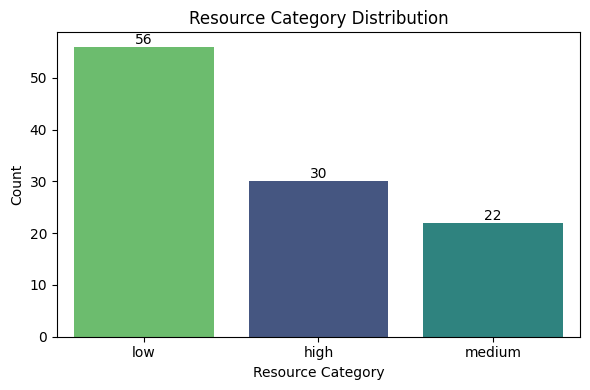

In [26]:
# some visualizations to show distribution of resource_category, script and family in fw2_lang_doc_distr_df
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))
ax = sns.countplot(
    data=fw2_lang_doc_distr_df,
    x="resource_category",
    hue="resource_category",
    order=fw2_lang_doc_distr_df["resource_category"]
          .value_counts()
          .index,
    palette="viridis",
    legend=False
)
plt.title("Resource Category Distribution")
plt.ylabel("Count")
plt.xlabel("Resource Category")
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge')   # shows the count in front of each bar
plt.tight_layout()
plt.show()

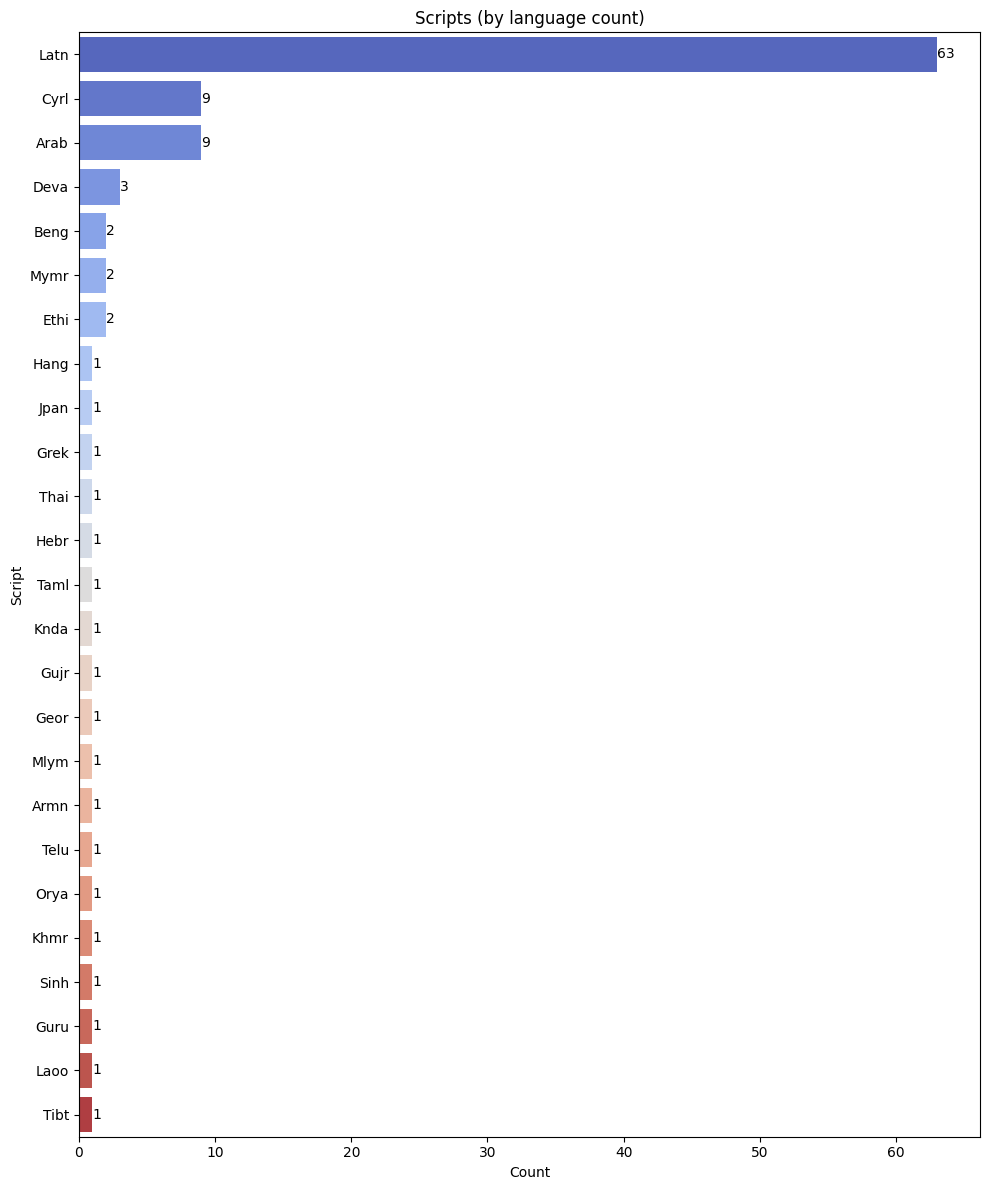

In [27]:
plt.figure(figsize=(10,12))
script_counts = fw2_lang_doc_distr_df["script"].value_counts()#.head(20) # choose head for top-n values
ax = sns.barplot(
    x=script_counts.values,
    y=script_counts.index,
    hue=script_counts.index,
    palette="coolwarm",
    legend=False
)
plt.title("Scripts (by language count)")
plt.xlabel("Count")
plt.ylabel("Script")
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge')
plt.tight_layout()
plt.show()


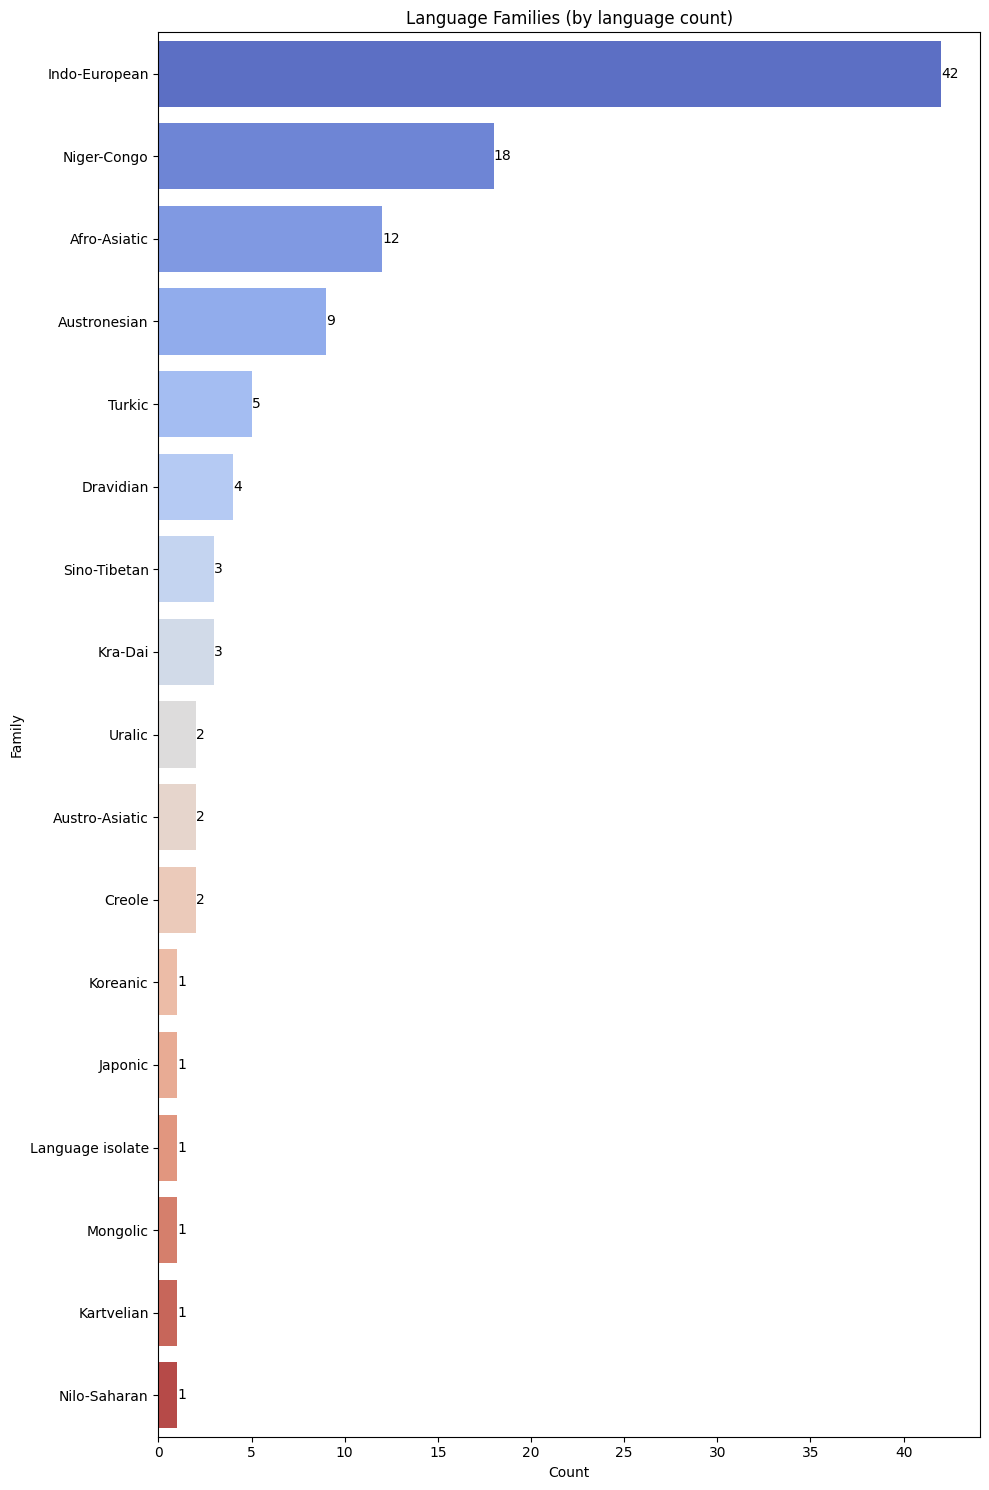

In [28]:
plt.figure(figsize=(10,15))
family_counts = fw2_lang_doc_distr_df["family"].value_counts()#.head(20) # choose head for top-n values
ax = sns.barplot(
    x=family_counts.values,
    y=family_counts.index,
    hue=family_counts.index,
    palette="coolwarm",
    legend=False
)
plt.title("Language Families (by language count)")
plt.xlabel("Count")
plt.ylabel("Family")
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge')
plt.tight_layout()
plt.show()

### Interactive Visualizations

In [32]:
# Show representation of resource_category, script and family through a single visualization?
# Create a hierarchical visualization using treemap
import plotly.express as px

# Prepare aggregated data for visualization
agg_data = fw2_lang_doc_distr_df.groupby(['family', 'script', 'resource_category']).size().reset_index(name='count')

# Create treemap visualization
fig = px.treemap(
    agg_data,
    path=['family', 'script', 'resource_category'],
    values='count',
    color='resource_category',
    color_discrete_map={
        'high': '#2ca02c',      # Green
        'medium': '#ff7f0e',    # Orange
        'low': '#d62728'        # Red
    },
    title='Language Distribution by Family, Script, and Resource Category',
    width=1200,
    height=800
)

# Update layout for better readability
fig.update_traces(
    textinfo='label+percent parent',
    texttemplate='%{label}<br>%{value} (%{percentParent:.1%})'
)
fig.update_layout(
    margin=dict(t=50, l=25, r=25, b=25)
)

# Show the plot
fig.show()

# Alternative: Create a sunburst plot for radial visualization
fig_sunburst = px.sunburst(
    agg_data,
    path=['family', 'script', 'resource_category'],
    values='count',
    color='resource_category',
    color_discrete_map={
        'high': '#2ca02c',
        'medium': '#ff7f0e',
        'low': '#d62728'
    },
    title='Hierarchical Language Distribution',
    width=1000,
    height=1000
)

fig_sunburst.update_layout(margin=dict(t=50, l=0, r=0, b=0))
fig_sunburst.show()


### Computing Embeddings
Generating vector representation for each language row

#### One-Hot Embedding

In [33]:
# Create one-hot vector of length 3 (resource_cat) + 40 (script) + 102 (language_family) = 145 for each language

# Define the mapping for the resource category
resource_cat_onehot = pd.get_dummies(
    fw2_lang_doc_distr_df["resource_category"], 
    prefix="rc"
)

# One‑hot for script (40 possible values) – column name is assumed to be "script"
script_onehot = pd.get_dummies(
    fw2_lang_doc_distr_df["script"], 
    prefix="script"
)

# One‑hot for language family (102 possible values) – column name is assumed to be "family"
family_onehot = pd.get_dummies(
    fw2_lang_doc_distr_df["family"], 
    prefix="family"
)

# Concatenate all one‑hot vectors
onehot_features_df = pd.concat(
    [resource_cat_onehot, script_onehot, family_onehot], 
    axis=1
)

print("\nOne‑hot feature shape:", onehot_features_df.shape)   # should be (n_lang, 145)


One‑hot feature shape: (108, 45)


#### LLM-based Semantic Embedding

In [ ]:
import requests

embedding_config = {
    'endpoint': 'http://lola.cs.uni-paderborn.de:9292/v1',
    'model_id': 'nomic-embed-text-v2-moe'
}

def get_embeddings(input_texts, embed_config=None):
    # Compute input embeddings
    if not embed_config:
        raise ValueError("embed_config must be provided")

    embed_endpoint = embed_config['endpoint']
    try:
        response = requests.post(
            embed_endpoint + '/embeddings',
            json={'input': input_texts, 'model': embed_config['model_id']},
            timeout=30
        )
        response.raise_for_status()
        payload = response.json()
    except Exception as exc:
        raise RuntimeError(f"Embedding request failed: {exc}") from exc

    if 'data' not in payload:
        raise RuntimeError(f"Unexpected embedding response: {payload}")

    embeddings = payload['data']
    if not embeddings:
        raise RuntimeError("Embedding service returned no vectors")

    return [entry['embedding'] for entry in embeddings]


In [37]:
import numpy as np
from tqdm import tqdm
# Cache for pre‑computed embeddings
embed_cache = {}

def get_cached_embedding(text: str):
    """Return cached embedding or compute it once."""
    if text not in embed_cache:
        # get_embeddings expects a list; we request a single embedding here
        embed_cache[text] = get_embeddings([text], embed_config=embedding_config)[0]
    return embed_cache[text]

# Build the final per‑row embeddings by concatenating the four component embeddings (name, resource_category, script, family).
BATCH_SIZE = 512
final_embeddings = []

for i in tqdm(range(0, len(fw2_lang_doc_distr_df), BATCH_SIZE),
              desc="Embedding rows"):
    batch_rows = fw2_lang_doc_distr_df.iloc[i:i+BATCH_SIZE]

    for _, row in batch_rows.iterrows():
        # Retrieve (or compute) each component embedding
        name_emb     = get_cached_embedding(row["name"] or "")
        cat_emb      = get_cached_embedding(row["resource_category"] or "")
        script_emb   = get_cached_embedding(row["script"] or "")
        family_emb   = get_cached_embedding(row["family"] or "")

        # Concatenate the four embeddings into one vector
        combined = np.concatenate([name_emb, cat_emb, script_emb, family_emb])
        final_embeddings.append(combined)

# Convert to a DataFrame aligned with the original rows
llm_embedding_df = pd.DataFrame(final_embeddings)
llm_embedding_df.columns = [
    f"llm_emb_{i}" for i in range(llm_embedding_df.shape[1])
]
llm_embedding_df.shape

Embedding rows:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding rows:   0%|          | 0/1 [00:05<?, ?it/s]


TypeError: 'NoneType' object is not subscriptable

### Clustering Languages
To allow easier sample selection based on cluster mediods

In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np
import matplotlib.pyplot as plt

# automatically pick the number of clusters
def select_optimal_clusters(features_df, k_min=2, k_max=200):
    """
    Try K‑Means with k = k_min … k_max and return the k that gives
    the highest silhouette score.
    """
    best_k = k_min
    best_score = -1.0

    # Keep all scores for visualisation
    ks_tested = []
    silhouette_scores = []

    # Limit the number of candidates if the dataset is small
    # max_candidates = min(k_max, len(features_df) // 10)  # at least 10 pts per cluster
    max_candidates = k_max
    for k in range(k_min, max_candidates + 1):
        kmeans = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init='auto',
            random_state=42
        )
        labels = kmeans.fit_predict(features_df)

        # Silhouette needs at least 2 clusters and less than n_samples‑1 labels
        if len(set(labels)) > 1 and len(set(labels)) < len(features_df):
            score = silhouette_score(features_df, labels, metric="euclidean")
            ks_tested.append(k)
            silhouette_scores.append(score)

            if score > best_score:
                best_score = score
                best_k = k
    
    # Visualise silhouette scores vs. number of clusters
    plt.figure(figsize=(8, 4))
    plt.plot(ks_tested, silhouette_scores, marker='o')
    plt.title('Silhouette Score vs. # of Clusters')
    plt.xlabel('Number of clusters (k)')
    plt.ylabel('Silhouette score')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.tight_layout()
    plt.show()

    return best_k, best_score

def get_max_clusters(features_df, k_max=200):
    # Count unique rows – each distinct feature vector can form at most one cluster
    n_unique = features_df.drop_duplicates().shape[0]

    # Cap the result at k_max to avoid overly granular clustering
    return min(n_unique, k_max)

# derive a list of nested sample sizes from the max cluster count
def build_nested_sample_sizes(max_clusters, min_size=5, num_steps=6):
    """
    Return a list like [5, 10, 25, 50, …] that grows roughly exponentially
    and never exceeds ``max_clusters``.
    """
    # Ensure the smallest size is at least 5 (or ``min_size``)
    start = max(min_size, 5)

    # Use geometric spacing to generate num_steps values including min and max
    geom = np.geomspace(start, max_clusters, num=num_steps) # Axel: no one cares about this distribution as long as we are showing the gradient of model's performance across the scale
    # Round, cast to int, drop duplicates, and keep only values ≤ max_clusters
    sizes = sorted({int(round(v)) for v in geom if int(round(v)) <= max_clusters})
    return sizes

In [19]:
# Cluster the languages into SAMPLE_SIZE clusters and then take the medoid (most central point) of each cluster as your representative
from sklearn.metrics import pairwise_distances

def compute_cluster_medoids(feature_approach_id, data_df, input_feature_df, nested_sample_sizes):

    max_sample_sizes = nested_sample_sizes[-1] # Largest sample size

    kmeans = KMeans(
        n_clusters=max_sample_sizes,
        init="k-means++",
        n_init='auto',
        random_state=42
    )
    cluster_labels = kmeans.fit_predict(input_feature_df)

    data_df[f"{feature_approach_id}_cluster_id"] = cluster_labels

    # Convert the one‑hot DataFrame to a NumPy array for fast distance computation
    X = input_feature_df.values
    distance_matrix = pairwise_distances(X, metric="euclidean")

    medoid_indices = []   # will store the original dataframe index of each medoid

    for clust_id in range(max_sample_sizes):
        # indices of rows belonging to the current cluster
        member_mask = (cluster_labels == clust_id)
        member_idxs = np.where(member_mask)[0]

        # slice the distance matrix to only those members
        sub_dm = distance_matrix[np.ix_(member_idxs, member_idxs)]

        # sum distances for each member and pick the smallest
        medoid_rel_idx = np.argmin(sub_dm.sum(axis=1))
        medoid_abs_idx = member_idxs[medoid_rel_idx]

        medoid_indices.append(medoid_abs_idx)
    
    return medoid_indices, cluster_labels, distance_matrix
    

In [20]:
# Visualize clusters in 2D space using t-SNE with interactive hover and medoid highlighting
from sklearn.manifold import TSNE
import plotly.express as px
import pandas as pd
import plotly.graph_objects as go

# Define reusable parameters
HOVER_COLUMNS = ['name', 'resource_category', 'script', 'family', 'cluster_id', 'is_medoid', 'TSNE1', 'TSNE2']
PLOT_WIDTH = 1500
PLOT_HEIGHT = 1000
COLOR_SCALE = 'Viridis'

def create_viz_df(features_df, cluster_labels, medoid_indices, data_df):
    """Create visualization DataFrame with t-SNE coordinates and metadata."""
    # Reduce dimensionality to 2D for visualization
    tsne = TSNE(n_components=2, random_state=42, perplexity=min(30, len(features_df)-1))
    X_tsne = tsne.fit_transform(features_df)
    
    # Create DataFrame for visualization
    viz_df = pd.DataFrame(X_tsne, columns=['TSNE1', 'TSNE2'])
    viz_df['cluster_id'] = cluster_labels
    viz_df['is_medoid'] = False
    viz_df.loc[medoid_indices, 'is_medoid'] = True
    
    # Merge with original data to get hover information
    viz_df = viz_df.join(data_df[['name', 'resource_category', 'script', 'family']])
    
    return viz_df

def create_hover_template():
    """Create hover template for plotly traces."""
    return "<b>%{hovertext}</b><br>" + \
           "TSNE1: %{customdata[5]:.3f}<br>" + \
           "TSNE2: %{customdata[6]:.3f}<br>" + \
           "Resource Category: %{customdata[0]}<br>" + \
           "Script: %{customdata[1]}<br>" + \
           "Family: %{customdata[2]}<br>" + \
           "Medoid: %{customdata[4]}<br>" + \
           "<extra></extra>"

def create_medoid_trace(medoid_data, hover_template):
    """Create plotly trace for medoid points."""
    return go.Scatter(
        x=medoid_data['TSNE1'],
        y=medoid_data['TSNE2'],
        mode='markers',
        marker=dict(
            size=12,
            color='red',
            symbol='circle',
            line=dict(width=1, color='darkred')
        ),
        hovertext=medoid_data['name'],
        customdata=medoid_data[HOVER_COLUMNS],
        hovertemplate=hover_template,
        name='Medoids'
    )

def style_plot(fig, sample_size):
    """Apply common styling to the plot."""
    # Hide the color bar (cluster legend)
    fig.update_layout(coloraxis_showscale=False)
    
    # Update layout with consistent styling
    fig.update_layout(
        title=f'Language Clusters (t-SNE)<br>{sample_size} clusters with medoids highlighted',
        width=PLOT_WIDTH,
        height=PLOT_HEIGHT,
        legend_title="Legend",
        hoverlabel=dict(
            bgcolor="white",
            font_size=12,
            font_family="Arial"
        )
    )
    return fig

def show_tsne_viz(features_df, cluster_labels, medoid_indices, data_df, max_cluster_count):
    # Create visualization DataFrame
    viz_df = create_viz_df(features_df, cluster_labels, medoid_indices, data_df)

    # Create base scatter plot for all points
    fig = px.scatter(
        viz_df,
        x='TSNE1',
        y='TSNE2',
        color='cluster_id',
        hover_name='name',
        hover_data={col: True for col in HOVER_COLUMNS},
        color_continuous_scale=COLOR_SCALE
    )

    # Get medoid data for separate trace
    medoid_data = viz_df[viz_df['is_medoid']]

    # Create and add medoid trace
    hover_template = create_hover_template()
    medoid_trace = create_medoid_trace(medoid_data, hover_template)
    fig.add_trace(medoid_trace)

    # Update traces and style the plot
    fig.update_traces(hovertemplate=hover_template, selector=dict(type='scatter'))
    fig = style_plot(fig, max_cluster_count)

    # Show the plot
    fig.show()

In [21]:
def cluster_languages(feature_approach_id, embeddings_df, data_df, cluster_count=None):
    # if not cluster_count:
    #     cluster_count, cluster_best_score = select_optimal_clusters(embeddings_df, k_min=5, k_max=embeddings_df.shape[0])
    # else:
    #     cluster_best_score = -1
    # print(f"Selected {cluster_count} clusters (silhouette={cluster_best_score:.4f})")
    cluster_count = get_max_clusters(embeddings_df, cluster_count)
    print(f"Selected {cluster_count} clusters")
    sample_sizes = build_nested_sample_sizes(cluster_count)
    print(f'Sample sizes: {sample_sizes}')
    medoid_indices, cluster_labels, dist_matrix = compute_cluster_medoids(feature_approach_id, data_df, embeddings_df, sample_sizes)
    print("Representative languages (medoids) computed")
    show_tsne_viz(embeddings_df, cluster_labels, medoid_indices, data_df, cluster_count)
    return medoid_indices, dist_matrix, sample_sizes

In [22]:
# Maximum number of languages to sample
# Note: Keeping the value one less to accomodate English at a later point
MAX_SAMPLE_SIZE = 199 # Only sample upto this size in-case the number of clusters is higher

#### Clustering One-Hot Embeddings

In [23]:
# Processing clustering of one-hot based embedding
print('For One-hot based embeddings: ')
onehot_medoid_indices, onehot_mediod_dist_matrix, onehot_sample_sizes = cluster_languages('onehot', onehot_features_df, fw2_lang_doc_distr_df, MAX_SAMPLE_SIZE)

For One-hot based embeddings: 
Selected 187 clusters
Sample sizes: [5, 10, 21, 44, 91, 187]
Representative languages (medoids) computed


#### Clustering Semantic Embeddings

In [24]:
# Processing clustering of LLM based embedding
print('For LLM based embeddings: ')
llm_medoid_indices, llm_mediod_dist_matrix, llm_sample_sizes = cluster_languages('llm', llm_embedding_df, fw2_lang_doc_distr_df, MAX_SAMPLE_SIZE)

For LLM based embeddings: 
Selected 199 clusters
Sample sizes: [5, 10, 22, 46, 95, 199]
Representative languages (medoids) computed


### Saving Sample Sets

In [25]:
# Choosing mediods in farthest first order to keep the nested samples diverse

def farthest_first_ordering(dist_matrix):
    """
    Greedy farthest‑point selection.
    Returns a list of medoid indices ordered from most central → most spread.
    """
    n = dist_matrix.shape[0]

    # start with the most central medoid (smallest total distance)
    start_idx = np.argmin(dist_matrix.sum(axis=1))
    ordered = [start_idx]

    # iteratively pick the point that maximizes its *minimum* distance to any point already in `ordered`
    remaining = set(range(n)) - {start_idx}
    while remaining:
        # distance of each candidate to the closest selected medoid
        min_dists = {
            i: min(dist_matrix[i, sel] for sel in ordered) for i in remaining
        }
        # candidate with the largest of those minima (i.e. farthest from the set)
        next_idx = max(min_dists, key=min_dists.get)
        ordered.append(next_idx)
        remaining.remove(next_idx)

    return ordered

def get_ordered_medoid_indices(medoid_indices, distance_matrix):
    # Compute pairwise distances between medoids (already done above)
    medoid_dist_matrix = distance_matrix[np.ix_(medoid_indices, medoid_indices)]
    # Use the new ordering instead of sorting by total distance
    ordered_medoid_idx = np.array(medoid_indices)[farthest_first_ordering(medoid_dist_matrix)]
    return ordered_medoid_idx

In [26]:
def save_nested_sample_sets(output_dir, sample_sizes, ordered_medoid_idx, data_df):
    os.makedirs(output_dir, exist_ok=True) # create directory if it does not exist

    for sz in sample_sizes:
        # Grab the first `sz` medoids from the ordered list
        nested_idxs = ordered_medoid_idx[:sz]

        # Build the representative DataFrame
        nested_rep_df = data_df.iloc[nested_idxs].reset_index(drop=True)

        # Save (e.g., `5_representative_mediods.csv`, `10_representative_mediods.csv`, …)
        csv_name = os.path.join(output_dir, f"{sz}_representative_mediods.csv")
        nested_rep_df.to_csv(csv_name, index=False)
        print(f"Saved {sz}‑sample")
    print('Finished saving samples.')

In [27]:
# Saving one-hot sampled languages
print('Saving one-hot reprensentative sets...')
onehot_ordered_medoids_indices = get_ordered_medoid_indices(onehot_medoid_indices, onehot_mediod_dist_matrix)
output_dir = os.path.join(FW_METADATA_DIR, "onehot_nested_samples")
save_nested_sample_sets(output_dir, onehot_sample_sizes, onehot_ordered_medoids_indices, fw2_lang_doc_distr_df)


Saving one-hot reprensentative sets...
Saved 5‑sample
Saved 10‑sample
Saved 21‑sample
Saved 44‑sample
Saved 91‑sample
Saved 187‑sample
Finished saving samples.


In [28]:
# Saving llm sampled languages
print('Saving llm reprensentative sets...')
llm_ordered_medoids_indices = get_ordered_medoid_indices(llm_medoid_indices, llm_mediod_dist_matrix)
output_dir = os.path.join(FW_METADATA_DIR, "llm_nested_samples")
save_nested_sample_sets(output_dir, llm_sample_sizes, llm_ordered_medoids_indices, fw2_lang_doc_distr_df)


Saving llm reprensentative sets...
Saved 5‑sample
Saved 10‑sample
Saved 22‑sample
Saved 46‑sample
Saved 95‑sample
Saved 199‑sample
Finished saving samples.
